# PR6: Regression (Linear and Polynomial) on California Housing

**Aim:** Predict house prices with Linear and Polynomial Regression and compare them using MSE, MAE and R².

| Metric | Meaning | Good value |
|---|---|---|
| MSE | average of squared errors | smaller |
| MAE | average of absolute errors | smaller |
| R² | how much variation the model explains | closer to 1 |

## 1. Load data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing

data = fetch_california_housing(as_frame=True)
df = data.frame            # target column is "MedHouseVal"

print(df.shape)
df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [2]:
print(df.isnull().sum().sum(), "missing values")
df.describe()

0 missing values


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


## 2. Data visualization (histograms and boxplots)

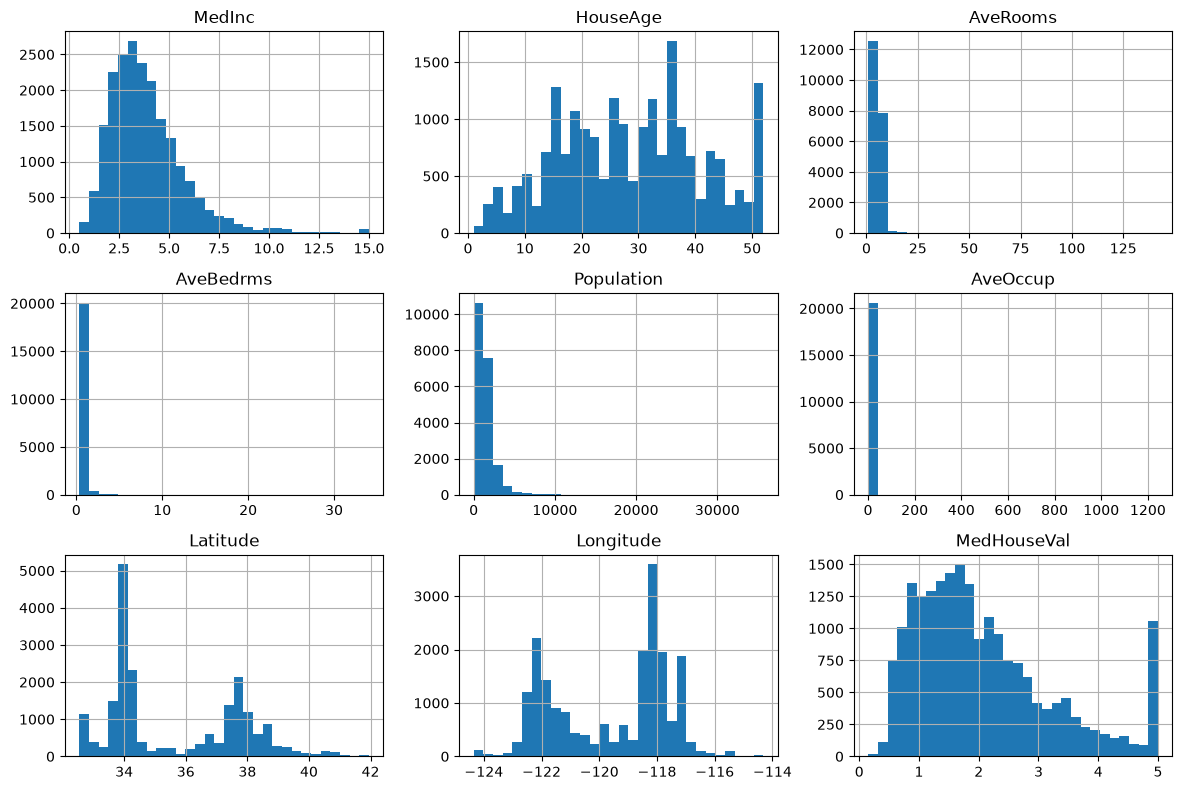

In [3]:
df.hist(bins=30, figsize=(12, 8))
plt.tight_layout()
plt.show()

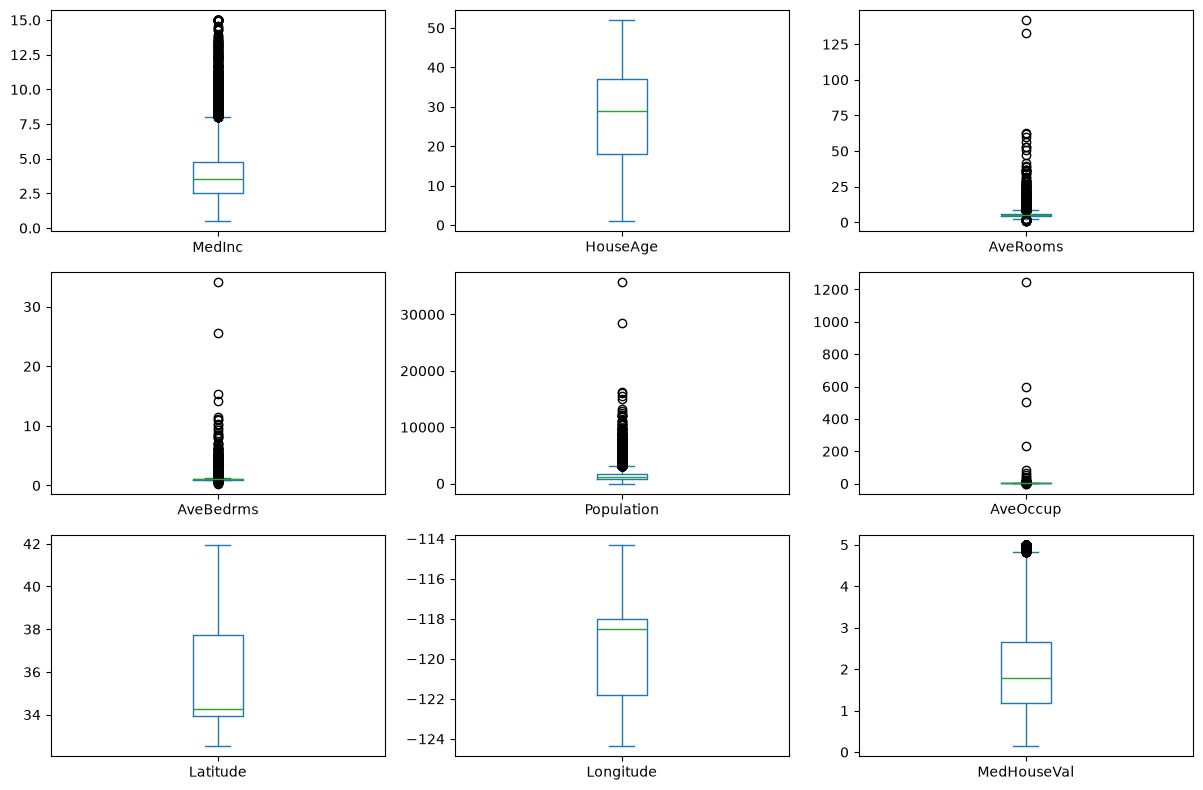

In [4]:
df.plot(kind="box", subplots=True, layout=(3, 3), figsize=(12, 8))
plt.tight_layout()
plt.show()

## 3. Split into train and test sets (80% / 20%)

`X` = input features, `y` = value to predict.

In [5]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (16512, 8) Test: (4128, 8)


## 4. Scale the features (fit on train only)

In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

## 5. Linear Regression

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

lin = LinearRegression()
lin.fit(X_train_s, y_train)
pred_lin = lin.predict(X_test_s)

lin_mse = mean_squared_error(y_test, pred_lin)
lin_mae = mean_absolute_error(y_test, pred_lin)
lin_r2 = r2_score(y_test, pred_lin)

print("Linear  MSE:", round(lin_mse, 4), " MAE:", round(lin_mae, 4), " R2:", round(lin_r2, 4))

Linear  MSE: 0.5559  MAE: 0.5332  R2: 0.5758


## 6. Polynomial Regression (degree 2)

`PolynomialFeatures` adds squares and products of the features (x², x*y ...). Then we use the same Linear Regression.

In [8]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)
X_train_p = poly.fit_transform(X_train_s)
X_test_p = poly.transform(X_test_s)

print("Features before:", X_train_s.shape[1], " after:", X_train_p.shape[1])

pol = LinearRegression()
pol.fit(X_train_p, y_train)
pred_pol = pol.predict(X_test_p)

pol_mse = mean_squared_error(y_test, pred_pol)
pol_mae = mean_absolute_error(y_test, pred_pol)
pol_r2 = r2_score(y_test, pred_pol)

print("Poly    MSE:", round(pol_mse, 4), " MAE:", round(pol_mae, 4), " R2:", round(pol_r2, 4))

Features before: 8  after: 45
Poly    MSE: 0.4643  MAE: 0.467  R2: 0.6457


## 7. Compare

In [9]:
result = pd.DataFrame({
    "Model": ["Linear", "Polynomial (deg 2)"],
    "MSE": [lin_mse, pol_mse],
    "MAE": [lin_mae, pol_mae],
    "R2": [lin_r2, pol_r2],
})
print(result.round(4))

                Model     MSE     MAE      R2
0              Linear  0.5559  0.5332  0.5758
1  Polynomial (deg 2)  0.4643  0.4670  0.6457


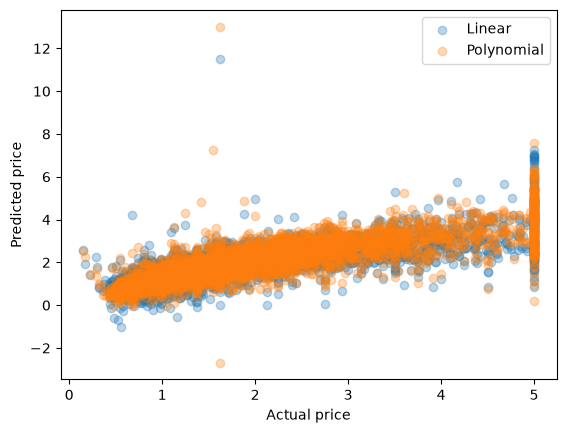

In [10]:
plt.scatter(y_test, pred_lin, alpha=0.3, label="Linear")
plt.scatter(y_test, pred_pol, alpha=0.3, label="Polynomial")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.legend()
plt.show()

## Viva points

- Linear Regression fits a straight line/plane: y = w1*x1 + w2*x2 + ... + b.
- Polynomial Regression is still linear regression, but on new features (x², x³ ...), so it can fit curves.
- A higher degree can **overfit** (great on train, bad on test).
- Lower MSE/MAE and higher R² means the better model. Here the polynomial model fits better (see the table).